# Exploring the SCDB data (and the rationale behind `config.py`)

This notebook loads the Supreme Court Database, defines the prediction problem, and checks every column decision in `src/config.py` against the data.

**Enforced rule:** anything that uses case *outcomes* looks at **training terms only (1946–2015)**, plus validation terms where a chart shows change over time. The **test terms (2021–2025) stay unseen** until task 4.2, so nothing we learn here can leak into the final score. Charts that show only counts (no outcomes) use all terms.

Note: Run with **Restart -> Run All** from the `.venv` (Python 3.13) kernel.

In [1]:
import sys
from pathlib import Path

# make the repo root importable so `src` works from notebooks/ian/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

from src import config
from src.data import add_circuit_features, handle_missing, load_data
from src.features import add_features
from src.split import split_by_term

DATA_PATH = REPO_ROOT / "data" / "SCDB_2026_01_caseCentered_Citation.csv"

In [2]:
# Chart style. The colors come from a colorblind-checked palette:
# blue / orange / aqua mark training / validation / test; gray is context.
BLUE, LIGHT_BLUE, ORANGE, AQUA = "#2a78d6", "#86b6ef", "#eb6834", "#1baf7a"
GRAY = "#c3c2b7"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID = "#fcfcfb", "#e1e0d9"
PART_COLORS = {"train": BLUE, "val": ORANGE, "test": AQUA}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": GRAY, "ytick.color": GRAY, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "font.size": 10, "legend.frameon": False,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "figure.dpi": 110,
})


def percent_axis(axis):
    """Show a 0-1 axis as percentages."""
    axis.set_major_formatter(PercentFormatter(1.0, decimals=0))


def label_bars(ax, bars, labels):
    """Write a value just past the end of each horizontal bar."""
    ax.bar_label(bars, labels=labels, padding=4, color=INK_2, fontsize=9)


def label_inside(ax, bars, labels):
    """Write each value in white just inside the end of its bar (for long bars a reference line crosses)."""
    for bar, text in zip(bars, labels):
        ax.annotate(text, (bar.get_width(), bar.get_y() + bar.get_height() / 2), xytext=(-5, 0),
                    textcoords="offset points", ha="right", va="center", color="white", fontsize=9)


def reference_line(ax, value, text):
    """A vertical hairline for a reference value, labelled at the top."""
    ax.axvline(value, color=MUTED, linewidth=1, zorder=0.9)  # behind bars and dots
    ax.text(value, 1.0, f" {text}", transform=ax.get_xaxis_transform(),
            color=INK_2, fontsize=9, va="bottom", ha="left")


def dumbbell(ax, labels, left, right, left_label, right_label):
    """Two dots per row joined by a line: compare two values for each item."""
    y = np.arange(len(labels))
    ax.hlines(y, np.minimum(left, right), np.maximum(left, right), color=GRID, linewidth=3, zorder=1)
    ax.scatter(left, y, s=70, color=LIGHT_BLUE, edgecolor=SURFACE, linewidth=2, zorder=3, label=left_label)
    ax.scatter(right, y, s=70, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3, label=right_label)
    ax.set_yticks(y, labels)
    ax.grid(axis="y", visible=False)

## 1. The machine learning problem

- **Question:** will the **petitioner** (the side that brought the case to the Supreme Court) win?
- **Type:** binary classification. Target = `partyWinning`: **1 = petitioner wins, 0 = petitioner loses**.
- **Rule:** use only information available **before the decision**. Columns filled in from the decision itself would give the answer away (section 8 shows how badly).
- **Success:** beat both baselines on unseen recent terms: "always predict the petitioner wins" and "the majority outcome of the previous 10 terms".
- **Benchmark:** Katz, Bommarito & Blackman (2017) reached 70.2% accuracy over 1816–2015 with a random forest, against 67.5% for their 10-term baseline.

## 2. Loading the data and choosing which cases to keep

The Supreme Court Database (2026 Release 01, case-centered, organized by citation) has one row per decision. `validate_columns()` from `config.py` confirms that each of the 53 columns sits in exactly one of the team's lists.

In [3]:
raw = pd.read_csv(DATA_PATH, encoding="latin-1", low_memory=False)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns; caseId unique: {raw['caseId'].is_unique}")
print("Every column classified exactly once:", config.validate_columns(raw))
print()
df = load_data(DATA_PATH)

9,409 rows x 53 columns; caseId unique: True
Every column classified exactly once: True

Number of rows loaded: 9,409
Number of rows after decisionType filter: 8,216
Number of rows after partyWinning filter: 8,211


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


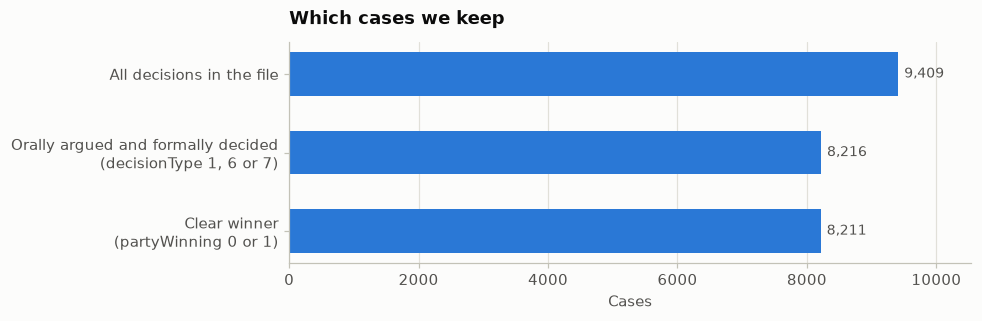

,cases,meaning,kept
decisionType,,,
1,7379,Opinion of the Court (orally argued),True
2,1010,Per curiam (not orally argued),False
4,66,Decree,False
5,117,Equally divided vote,False
6,582,Per curiam (orally argued),True
7,255,Judgment of the Court (orally argued),True


,cases after the decisionType filter
partyWinning,
1 = petitioner won,5192
0 = petitioner lost,3019
2 = unclear,5


In [4]:
DECISION_TYPES = {
    1: "Opinion of the Court (orally argued)", 2: "Per curiam (not orally argued)",
    4: "Decree", 5: "Equally divided vote", 6: "Per curiam (orally argued)",
    7: "Judgment of the Court (orally argued)", 8: "Seriatim opinions",
}
after_type = raw[raw["decisionType"].isin([1, 6, 7])]

funnel = pd.Series({
    "All decisions in the file": len(raw),
    "Orally argued and formally decided\n(decisionType 1, 6 or 7)": len(after_type),
    "Clear winner\n(partyWinning 0 or 1)": len(df),
})
fig, ax = plt.subplots(figsize=(8, 2.6))
bars = ax.barh(funnel.index[::-1], funnel.values[::-1], height=0.55, color=BLUE)
label_bars(ax, bars, [f"{v:,}" for v in funnel.values[::-1]])
ax.set_xlim(0, len(raw) * 1.12)
ax.set_xlabel("Cases")
ax.grid(axis="y", visible=False)
ax.set_title("Which cases we keep")
plt.show()

types = raw["decisionType"].value_counts().sort_index().rename("cases").to_frame()
types["meaning"] = [DECISION_TYPES.get(int(t), "?") for t in types.index]
types["kept"] = types.index.isin([1, 6, 7])
display(types)
display(after_type["partyWinning"].value_counts(dropna=False)
        .rename(index={1: "1 = petitioner won", 0: "0 = petitioner lost", 2: "2 = unclear"})
        .rename("cases after the decisionType filter").to_frame())

**Why these filters:** cases decided without oral argument (mostly short per curiam orders) and decrees are a different kind of decision from the argued cases we want to predict. The 5 cases where the winner is "unclear" have no target, so they are dropped. That leaves **8,211 cases**.

## 3. The target over time

The petitioner wins most of the time, but **the share moves a lot over time**: the 10-term average swings between about 55% and 71%, and recent terms (67% in validation) sit above the training average (63%). This is the main reason we split by term instead of at random: a model must be judged on years it has never seen, which may not look like the past. It also explains why "always predict the petitioner wins" is hard to beat on recent terms. Test terms are not plotted here because their outcomes stay unseen.

Training terms: the petitioner wins 62.8% of cases


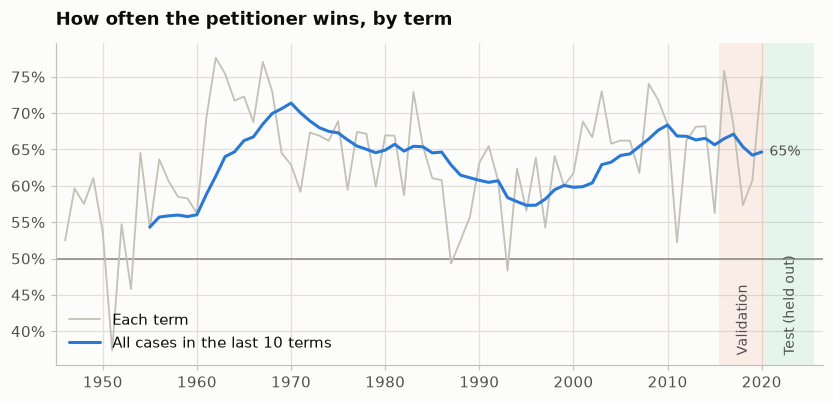

,cases,win_rate,last_10_terms
term,,,
1946,141,0.525,NaN
1951,91,0.374,NaN
1956,121,0.636,0.557
1961,101,0.693,0.588
1966,112,0.688,0.667
1971,147,0.592,0.700
1976,143,0.594,0.663
1981,148,0.669,0.657
1986,153,0.608,0.646


In [5]:
seen = df[df["term"] <= config.VALIDATION_END_TERM]
by_term = seen.groupby("term")["partyWinning"].agg(wins="sum", cases="size")
by_term["win_rate"] = by_term["wins"] / by_term["cases"]
by_term["last_10_terms"] = by_term["wins"].rolling(10).sum() / by_term["cases"].rolling(10).sum()

train_terms = by_term.loc[:config.TRAIN_END_TERM]
train_rate = train_terms["wins"].sum() / train_terms["cases"].sum()
print(f"Training terms: the petitioner wins {train_rate:.1%} of cases")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(by_term.index, by_term["win_rate"], color=GRAY, linewidth=1.2, label="Each term")
ax.plot(by_term.index, by_term["last_10_terms"], color=BLUE, label="All cases in the last 10 terms")
ax.axvspan(config.VALIDATION_START_TERM - 0.5, config.VALIDATION_END_TERM + 0.5, color=ORANGE, alpha=0.10, linewidth=0)
ax.axvspan(config.TEST_START_TERM - 0.5, config.TEST_END_TERM + 0.5, color=AQUA, alpha=0.10, linewidth=0)
for start, end, text in [(config.VALIDATION_START_TERM, config.VALIDATION_END_TERM, "Validation"),
                         (config.TEST_START_TERM, config.TEST_END_TERM, "Test (held out)")]:
    ax.text((start + end) / 2, 0.03, text, transform=ax.get_xaxis_transform(), rotation=90,
            ha="center", va="bottom", color=INK_2, fontsize=9)
ax.axhline(0.5, color=MUTED, linewidth=1, zorder=1)
ax.annotate(f"{by_term['last_10_terms'].iloc[-1]:.0%}", (by_term.index[-1], by_term["last_10_terms"].iloc[-1]),
            xytext=(5, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
percent_axis(ax.yaxis)
ax.set_xlim(1945, 2026.5)
ax.legend(loc="lower left")
ax.set_title("How often the petitioner wins, by term")
plt.show()

display(by_term[["cases", "win_rate", "last_10_terms"]].iloc[::5].round(3))

## 4. Splitting by term

`split_by_term()` puts terms up to 2015 in training, 2016–2020 in validation, and 2021–2025 in test. The Court also hears far fewer cases now than it did in the 1970s and 80s, which is why the validation and test parts are small (about 60 cases a term).

train: 7,611 cases, terms 1946-2015, petitioner win rate 62.8%
  val:   305 cases, terms 2016-2020, petitioner win rate 67.2%
 test:   295 cases, terms 2021-2025, petitioner win rate 69.2%


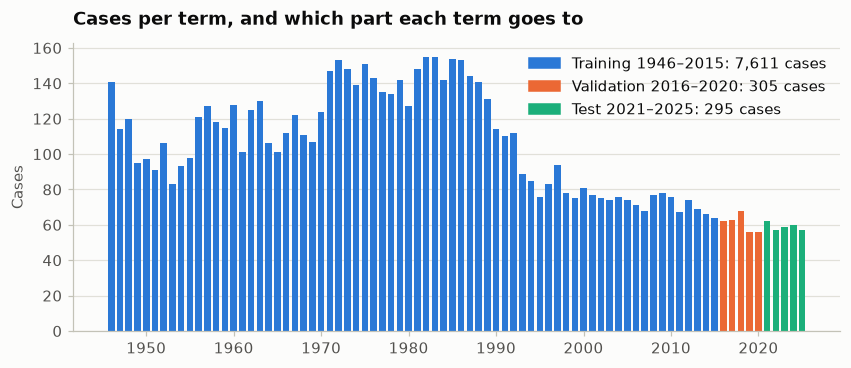

In [6]:
features = add_circuit_features(add_features(df))
X_train, y_train, X_val, y_val, X_test, y_test = split_by_term(features, config.FEATURE_COLUMNS)

# every column (not just features) for the training terms, for exploring below
train = features.loc[X_train.index]

counts = features.groupby("term").size()
part = np.select([counts.index <= config.TRAIN_END_TERM, counts.index <= config.VALIDATION_END_TERM],
                 ["train", "val"], "test")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(counts.index, counts.values, width=0.75, color=[PART_COLORS[p] for p in part])
ax.legend(handles=[
    Patch(color=BLUE, label=f"Training 1946–{config.TRAIN_END_TERM}: {len(X_train):,} cases"),
    Patch(color=ORANGE, label=f"Validation {config.VALIDATION_START_TERM}–{config.VALIDATION_END_TERM}: {len(X_val):,} cases"),
    Patch(color=AQUA, label=f"Test {config.TEST_START_TERM}–{config.TEST_END_TERM}: {len(X_test):,} cases"),
], loc="upper right")
ax.grid(axis="x", visible=False)
ax.set_ylabel("Cases")
ax.set_title("Cases per term, and which part each term goes to")
plt.show()

## 5. What happens to each of the 53 columns

`config.py` puts every column in one group, with a one-line reason. Only the blue groups reach the model. The table lists every column with its reason.

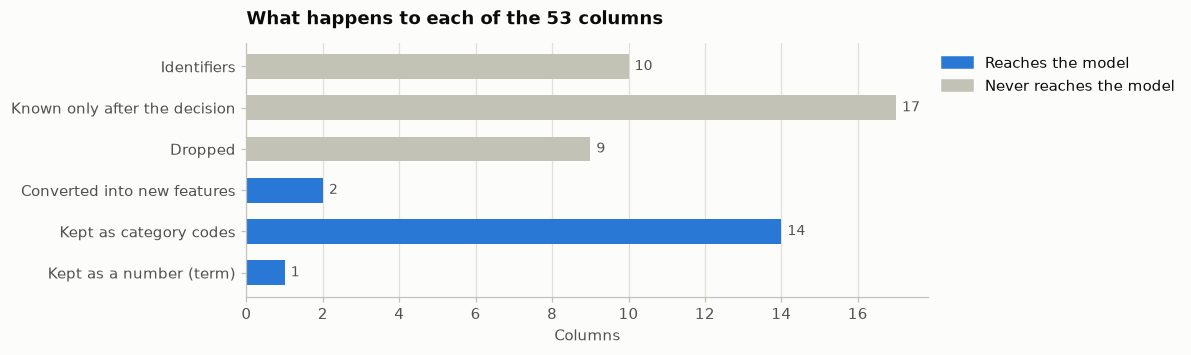

New features added in src/features.py and src/data.py: ['petitioner_is_us', 'respondent_is_us', 'was_reargued', 'argument_month', 'caseSourceCircuit', 'caseOriginCircuit']


,group,reason in config.py
column,,
caseId,Identifiers,Drop: database identifier.
docketId,Identifiers,Drop: database identifier.
caseIssuesId,Identifiers,Drop: issue-level identifier.
voteId,Identifiers,Drop: vote-level identifier.
usCite,Identifiers,Drop: U.S. Reports citation.
sctCite,Identifiers,Drop: Supreme Court Reporter citation.
ledCite,Identifiers,Drop: Lawyers' Edition citation.
lexisCite,Identifiers,Drop: Lexis citation.
docket,Identifiers,Drop: case docket number.


In [7]:
groups = {
    "Identifiers": config.ID_COLUMNS,
    "Known only after the decision": config.POST_DECISION_COLUMNS,
    "Dropped": config.OTHER_DROP_COLUMNS,
    "Converted into new features": config.CONVERT_COLUMNS,
    "Kept as category codes": config.CATEGORICAL_FEATURES,
    "Kept as a number (term)": config.NUMERIC_FEATURES,
}
used = {"Converted into new features", "Kept as category codes", "Kept as a number (term)"}
sizes = pd.Series({name: len(cols) for name, cols in groups.items()})

fig, ax = plt.subplots(figsize=(8, 3))
order = sizes.index[::-1]
bars = ax.barh(order, sizes[order], height=0.6, color=[BLUE if g in used else GRAY for g in order])
label_bars(ax, bars, [str(v) for v in sizes[order]])
ax.legend(handles=[Patch(color=BLUE, label="Reaches the model"), Patch(color=GRAY, label="Never reaches the model")],
          loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_xlabel("Columns")
ax.grid(axis="y", visible=False)
ax.set_title(f"What happens to each of the {sizes.sum()} columns")
plt.show()

print("New features added in src/features.py and src/data.py:",
      config.DERIVED_NUMERIC_FEATURES + config.DERIVED_CATEGORICAL_FEATURES)

reasons = pd.DataFrame(
    [(col, name, config.COLUMN_REASONS[col]) for name, cols in groups.items() for col in cols],
    columns=["column", "group", "reason in config.py"],
).set_index("column")
with pd.option_context("display.max_rows", 60, "display.max_colwidth", 90):
    display(reasons)

## 6. Missing values (training terms)

Most columns are numeric codes, and a blank means "not recorded". The chart shows every candidate column with any blanks; identifier and post-decision columns are left out because they are never features anyway.

- The **dropped** columns (blue) include the five `...State` columns (72–92% blank) and `lawMinor` (82% blank free text). `lawType` and `lawSupp` are dropped for a different reason: they are coded by reading the opinion.
- `dateRearg` is 98% blank, but that is the information itself: a blank means the case was **never reargued**, which becomes the `was_reargued` feature.
- `adminAction` is 70% blank but kept: Katz et al. used it, and a blank mostly means no federal agency acted before the case. Blanks become their own `-1` category.

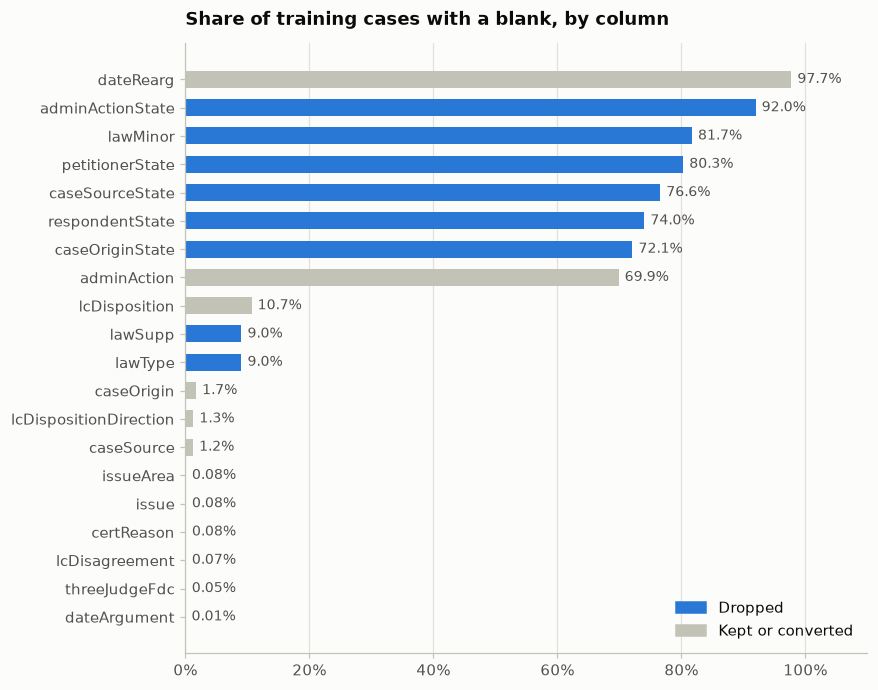

,blank,decision,reason in config.py
dateRearg,0.9773,Converted,Convert: create reargument indicator.
adminActionState,0.9197,Dropped,Drop: high percentage of missing values.
lawMinor,0.8170,Dropped,Drop: mostly missing free-text data.
petitionerState,0.8029,Dropped,Drop: high percentage of missing values.
caseSourceState,0.7659,Dropped,Drop: high percentage of missing values.
respondentState,0.7402,Dropped,Drop: high percentage of missing values.
caseOriginState,0.7211,Dropped,Drop: high percentage of missing values.
adminAction,0.6987,Kept,Retain: administrative action taken.
lcDisposition,0.1067,Kept,Retain: lower court disposition.
lawType,0.0904,Dropped,Drop: coded using the final opinion.


In [8]:
candidates = [c for c in raw.columns if c not in config.ID_COLUMNS + config.POST_DECISION_COLUMNS]
missing = train[candidates].isna().mean()
missing = missing[missing > 0].sort_values()

def decision(col):
    if col in config.OTHER_DROP_COLUMNS:
        return "Dropped"
    return "Converted" if col in config.CONVERT_COLUMNS else "Kept"

fig, ax = plt.subplots(figsize=(8, 0.3 * len(missing) + 1.2))
bars = ax.barh(missing.index, missing.values, height=0.6,
               color=[BLUE if decision(c) == "Dropped" else GRAY for c in missing.index])
label_bars(ax, bars, [f"{v:.1%}" if v >= 0.01 else f"{v:.2%}" for v in missing.values])
percent_axis(ax.xaxis)
ax.set_xlim(0, 1.1)
ax.legend(handles=[Patch(color=BLUE, label="Dropped"), Patch(color=GRAY, label="Kept or converted")], loc="lower right")
ax.grid(axis="y", visible=False)
ax.set_title("Share of training cases with a blank, by column")
plt.show()

table = pd.DataFrame({"blank": missing.sort_values(ascending=False).round(4)})
table["decision"] = [decision(c) for c in table.index]
table["reason in config.py"] = [config.COLUMN_REASONS[c] for c in table.index]
with pd.option_context("display.max_colwidth", 80):
    display(table)

## 7. Does a blank tell us anything about who wins?

If blank cases had a very different win rate from filled ones, "is it blank?" would itself be a useful feature, and dropping the column would throw that away. For the dropped columns it isn't: **the petitioner wins about as often whether the column is blank or filled** (within 3 points). Combined with how empty they are, and Katz et al. not using them, that is why they go.

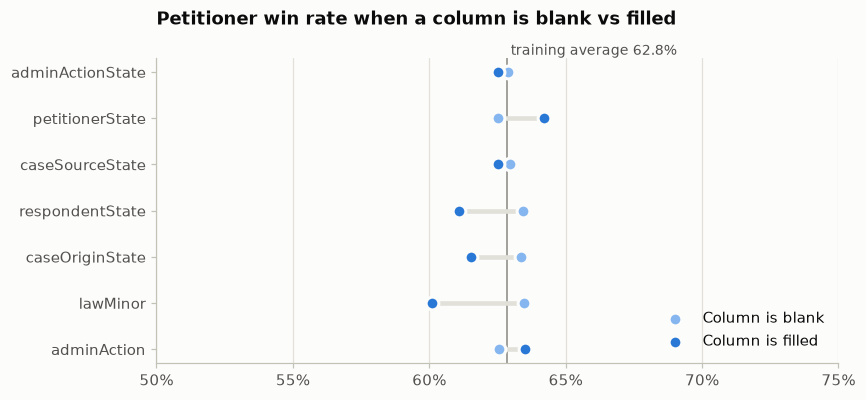

,blank,win rate when blank,win rate when filled,difference (points)
column,,,,
adminActionState,0.920,0.629,0.625,0.351
petitionerState,0.803,0.625,0.642,-1.690
caseSourceState,0.766,0.629,0.625,0.430
respondentState,0.740,0.635,0.611,2.351
caseOriginState,0.721,0.634,0.615,1.840
lawMinor,0.817,0.635,0.601,3.375
adminAction,0.699,0.626,0.635,-0.936


In [9]:
cols = ["adminActionState", "petitionerState", "caseSourceState", "respondentState", "caseOriginState", "lawMinor", "adminAction"]
won = train["partyWinning"]
gap = pd.DataFrame([
    {"column": col,
     "blank": train[col].isna().mean(),
     "win rate when blank": won[train[col].isna()].mean(),
     "win rate when filled": won[train[col].notna()].mean()}
    for col in cols
]).set_index("column")
gap["difference (points)"] = 100 * (gap["win rate when blank"] - gap["win rate when filled"])

fig, ax = plt.subplots(figsize=(8, 3.6))
dumbbell(ax, gap.index, gap["win rate when blank"], gap["win rate when filled"], "Column is blank", "Column is filled")
reference_line(ax, train_rate, f"training average {train_rate:.1%}")
percent_axis(ax.xaxis)
ax.set_xlim(0.5, 0.75)
ax.invert_yaxis()
ax.legend(loc="lower right")
ax.set_title("Petitioner win rate when a column is blank vs filled", pad=22)
plt.show()

display(gap.round(3))

## 8. Two special cases: `threeJudgeFdc` and `chief`

**`threeJudgeFdc`** (was the case heard by a three-judge federal district court?) has only 20 blanks, but filling them with the usual `-1` would invent a category that hardly exists. Nearly all blanks reached the Court **by petition** (`jurisdiction` = 1), and almost every petition case has `threeJudgeFdc` = 0, so the blanks are filled with **0**.

**`chief`** (the Chief Justice's name) is dropped because `naturalCourt`, which we keep, already says it: every natural court period has exactly one chief.

In [10]:
blank = features["threeJudgeFdc"].isna()
term = features["term"]
parts = np.select([term <= config.TRAIN_END_TERM, term <= config.VALIDATION_END_TERM], ["training", "validation"], "test")
print("threeJudgeFdc blanks per part:", pd.Series(parts[blank]).value_counts().reindex(["training", "validation", "test"]).to_dict())
print("jurisdiction of the blank cases:", features.loc[blank, "jurisdiction"].value_counts().to_dict(), "(1 = petition)")
petition = train[(train["jurisdiction"] == 1) & train["threeJudgeFdc"].notna()]
print(f"Training petition cases with threeJudgeFdc = 0: {(petition['threeJudgeFdc'] == 0).mean():.1%} of {len(petition):,}")
print()

per_court = features.groupby("naturalCourt")["chief"].nunique()
print(f"{len(per_court)} natural courts; the most chiefs any one of them has: {per_court.max()}")
display(features.groupby("chief")
        .agg(natural_courts=("naturalCourt", "nunique"), first_term=("term", "min"), last_term=("term", "max"))
        .sort_values("first_term"))

threeJudgeFdc blanks per part: {'training': 4, 'validation': 9, 'test': 7}
jurisdiction of the blank cases: {1.0: 19, 9.0: 1} (1 = petition)
Training petition cases with threeJudgeFdc = 0: 99.9% of 6,220

36 natural courts; the most chiefs any one of them has: 1


,natural_courts,first_term,last_term
chief,,,
Vinson,2,1946,1952
Warren,11,1953,1968
Burger,7,1969,1985
Rehnquist,7,1986,2004
Roberts,9,2005,2025


## 9. Why post-decision columns can never be features

`caseDisposition` records what the Court did with the lower court's decision. It is only known **after** the decision, and it nearly *is* the answer: when the Court affirms, the petitioner almost never wins, and when it reverses, the petitioner almost always does. A model given this column would look brilliant in testing and be useless for prediction. The other 16 post-decision columns leak in the same way, some less obviously (for example vote counts and the opinion's author).

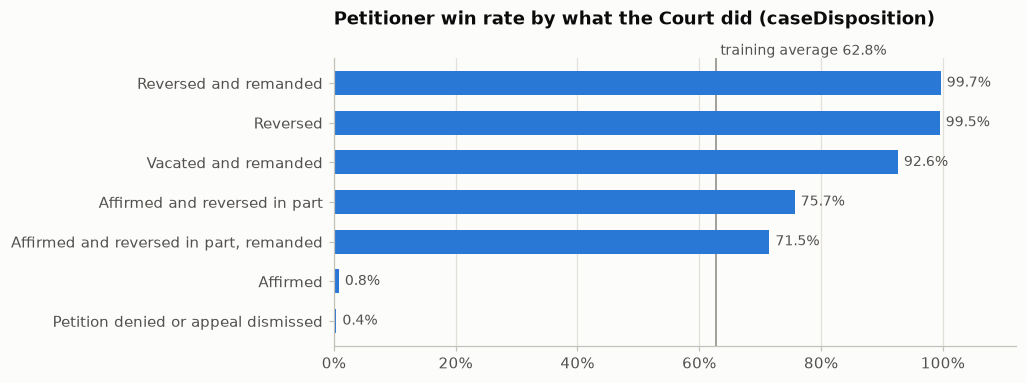

Groups with fewer than 30 training cases are left out of the chart; all groups:


,win_rate,cases
Affirmed,0.008,2437
Reversed and remanded,0.997,2090
Reversed,0.995,1770
Vacated and remanded,0.926,732
Petition denied or appeal dismissed,0.004,241
"Affirmed and reversed in part, remanded",0.715,158
Affirmed and reversed in part,0.757,74
Vacated,0.778,18
"Stay, petition or motion granted",0.667,15
Certification,0.556,9


In [11]:
DISPOSITIONS = {
    1: "Stay, petition or motion granted", 2: "Affirmed", 3: "Reversed", 4: "Reversed and remanded",
    5: "Vacated and remanded", 6: "Affirmed and reversed in part", 7: "Affirmed and reversed in part, remanded",
    8: "Vacated", 9: "Petition denied or appeal dismissed", 10: "Certification", 11: "No disposition",
}
by_disp = train.groupby("caseDisposition")["partyWinning"].agg(win_rate="mean", cases="size")
by_disp.index = [DISPOSITIONS.get(int(c), str(c)) for c in by_disp.index]
shown = by_disp[by_disp["cases"] >= 30].sort_values("win_rate")

fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.barh(shown.index, shown["win_rate"], height=0.6, color=BLUE)
label_bars(ax, bars, [f"{v:.1%}" for v in shown["win_rate"]])
reference_line(ax, train_rate, f"training average {train_rate:.1%}")
percent_axis(ax.xaxis)
ax.set_xlim(0, 1.12)
ax.grid(axis="y", visible=False)
ax.set_title("Petitioner win rate by what the Court did (caseDisposition)", pad=22)
plt.show()

print("Groups with fewer than 30 training cases are left out of the chart; all groups:")
display(by_disp.sort_values("cases", ascending=False).round(3))

## 10. Rare categories

Several kept columns have hundreds of codes, and many codes appear only a handful of times in training. A model can't learn anything reliable from a code it has seen 3 times, so the encoders in `src/preprocess.py` merge every code seen **fewer than 10 times** (`RARE_CATEGORY_THRESHOLD` in `config.py`) into one "other" group. The counts below use the real cleaning step, `handle_missing()`, so blanks are their own code.

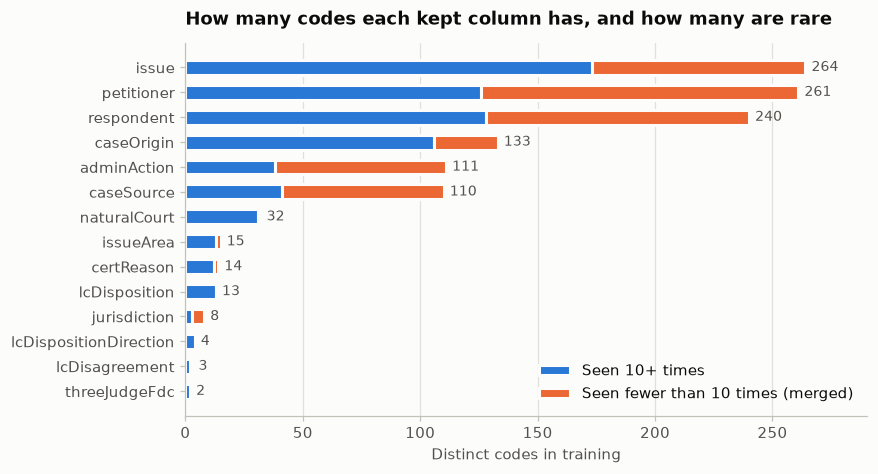

,codes,common codes,rare codes,cases with a rare code
column,,,,
threeJudgeFdc,2,2,0,0
lcDisagreement,3,2,1,5
lcDispositionDirection,4,4,0,0
jurisdiction,8,3,5,23
lcDisposition,13,13,0,0
certReason,14,12,2,9
issueArea,15,13,2,8
naturalCourt,32,31,1,5
caseSource,110,41,69,274


In [12]:
cleaned = handle_missing(train[config.CATEGORICAL_FEATURES])
rows = []
for col in config.CATEGORICAL_FEATURES:
    counts = cleaned[col].value_counts()
    rare = counts < config.RARE_CATEGORY_THRESHOLD
    rows.append({"column": col, "codes": len(counts), "common codes": int((~rare).sum()),
                 "rare codes": int(rare.sum()), "cases with a rare code": int(counts[rare].sum())})
rare_table = pd.DataFrame(rows).set_index("column").sort_values("codes")

fig, ax = plt.subplots(figsize=(8, 4.4))
common = ax.barh(rare_table.index, rare_table["common codes"], height=0.6, color=BLUE,
                 edgecolor=SURFACE, linewidth=2, label=f"Seen {config.RARE_CATEGORY_THRESHOLD}+ times")
rare = ax.barh(rare_table.index, rare_table["rare codes"], left=rare_table["common codes"], height=0.6, color=ORANGE,
               edgecolor=SURFACE, linewidth=2, label=f"Seen fewer than {config.RARE_CATEGORY_THRESHOLD} times (merged)")
label_bars(ax, rare, [str(v) for v in rare_table["codes"]])
ax.set_xlim(0, rare_table["codes"].max() * 1.1)
ax.set_xlabel("Distinct codes in training")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("How many codes each kept column has, and how many are rare")
plt.show()

display(rare_table)

## 11. Which features carry signal? (training terms)

A quick look at how the petitioner's win rate changes with some of the features. These are one-at-a-time comparisons, so they hint at what a model can use; they don't prove it.

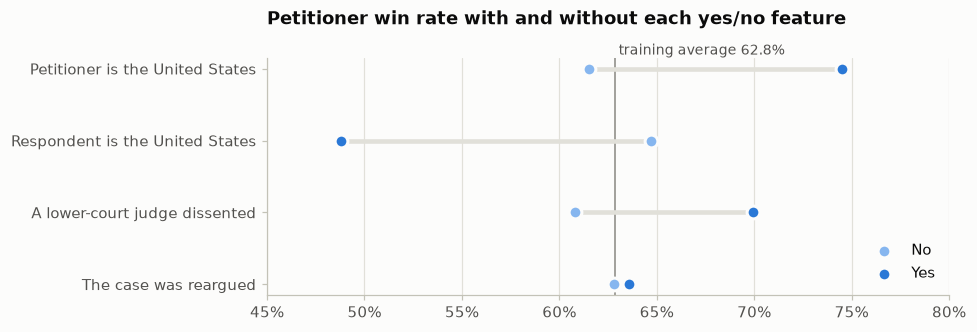

,win rate if no,win rate if yes,cases with yes,difference (points)
feature,,,,
Petitioner is the United States,0.615,0.745,776,12.963
Respondent is the United States,0.647,0.488,883,-15.874
A lower-court judge dissented,0.608,0.699,1707,9.123
The case was reargued,0.628,0.636,173,0.758


In [13]:
BINARY = {
    "petitioner_is_us": "Petitioner is the United States",
    "respondent_is_us": "Respondent is the United States",
    "lcDisagreement": "A lower-court judge dissented",
    "was_reargued": "The case was reargued",
}
signal = pd.DataFrame([
    {"feature": label,
     "win rate if no": won[train[col] == 0].mean(),
     "win rate if yes": won[train[col] == 1].mean(),
     "cases with yes": int((train[col] == 1).sum())}
    for col, label in BINARY.items()
]).set_index("feature")
signal["difference (points)"] = 100 * (signal["win rate if yes"] - signal["win rate if no"])

fig, ax = plt.subplots(figsize=(8, 2.8))
dumbbell(ax, signal.index, signal["win rate if no"], signal["win rate if yes"], "No", "Yes")
reference_line(ax, train_rate, f"training average {train_rate:.1%}")
percent_axis(ax.xaxis)
ax.set_xlim(0.45, 0.8)
ax.invert_yaxis()
ax.legend(loc="lower right")
ax.set_title("Petitioner win rate with and without each yes/no feature", pad=22)
plt.show()

display(signal.round(3))

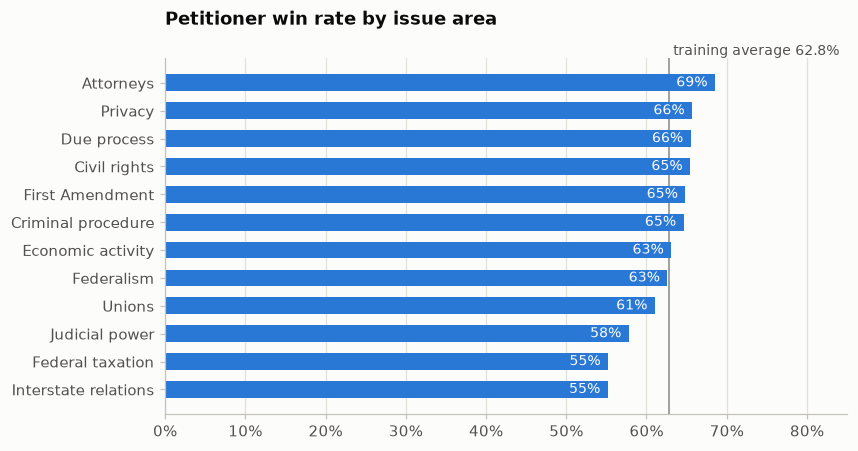

Issue areas with fewer than 30 training cases are left out of the chart; all of them:


,win_rate,cases
Criminal procedure,0.646,1648
Economic activity,0.631,1601
Civil rights,0.654,1192
Judicial power,0.578,988
First Amendment,0.648,586
Federalism,0.626,361
Unions,0.610,344
Due process,0.655,316
Federal taxation,0.552,297
Privacy,0.657,102


In [14]:
ISSUE_AREAS = {
    1: "Criminal procedure", 2: "Civil rights", 3: "First Amendment", 4: "Due process", 5: "Privacy",
    6: "Attorneys", 7: "Unions", 8: "Economic activity", 9: "Judicial power", 10: "Federalism",
    11: "Interstate relations", 12: "Federal taxation", 13: "Miscellaneous", 14: "Private action",
}
by_issue = train.groupby("issueArea")["partyWinning"].agg(win_rate="mean", cases="size")
by_issue.index = [ISSUE_AREAS.get(int(c), str(c)) for c in by_issue.index]
shown = by_issue[by_issue["cases"] >= 30].sort_values("win_rate")

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(shown.index, shown["win_rate"], height=0.6, color=BLUE)
label_inside(ax, bars, [f"{v:.0%}" for v in shown["win_rate"]])
reference_line(ax, train_rate, f"training average {train_rate:.1%}")
percent_axis(ax.xaxis)
ax.set_xlim(0, 0.85)
ax.grid(axis="y", visible=False)
ax.set_title("Petitioner win rate by issue area", pad=22)
plt.show()

print("Issue areas with fewer than 30 training cases are left out of the chart; all of them:")
display(by_issue.sort_values("cases", ascending=False).round(3))

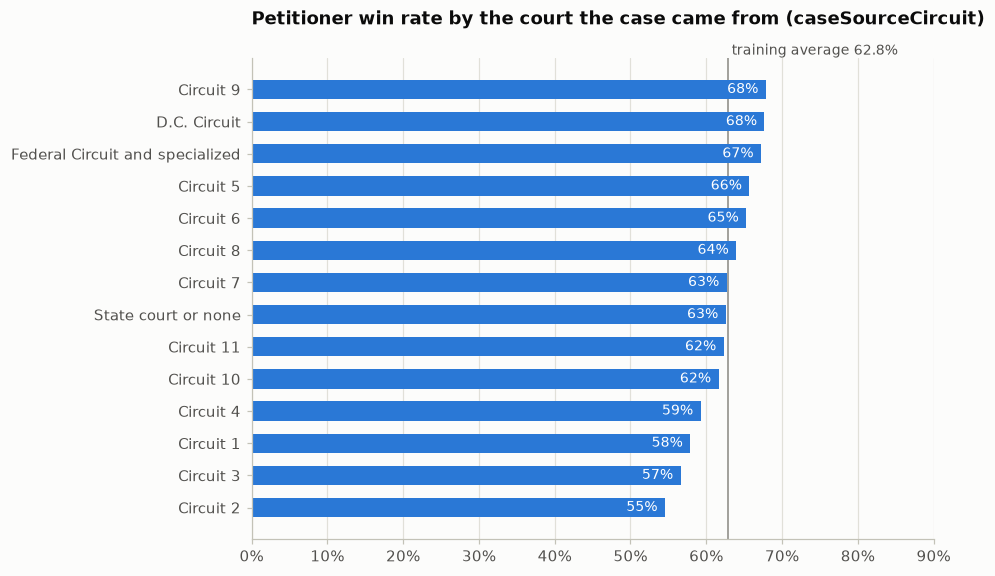

Groups with fewer than 30 training cases are left out of the chart; all of them:


,win_rate,cases
State court or none,0.626,1782
Circuit 9,0.679,1002
Circuit 2,0.546,669
Circuit 5,0.657,653
D.C. Circuit,0.677,520
Circuit 7,0.627,496
Circuit 6,0.653,455
Circuit 3,0.566,408
Circuit 4,0.593,378
Circuit 8,0.640,344


In [15]:
CIRCUITS = {0: "State court or none", **{n: f"Circuit {n}" for n in range(1, 12)}, 12: "D.C. Circuit",
            13: "Federal Circuit and specialized", 14: "Military courts", 22: "Tax and bankruptcy courts",
            99: "Other special courts"}
by_circuit = train.groupby("caseSourceCircuit")["partyWinning"].agg(win_rate="mean", cases="size")
by_circuit.index = [CIRCUITS.get(int(c), str(c)) for c in by_circuit.index]
shown = by_circuit[by_circuit["cases"] >= 30].sort_values("win_rate")

fig, ax = plt.subplots(figsize=(8, 0.32 * len(shown) + 1.2))
bars = ax.barh(shown.index, shown["win_rate"], height=0.6, color=BLUE)
label_inside(ax, bars, [f"{v:.0%}" for v in shown["win_rate"]])
reference_line(ax, train_rate, f"training average {train_rate:.1%}")
percent_axis(ax.xaxis)
ax.set_xlim(0, 0.9)
ax.grid(axis="y", visible=False)
ax.set_title("Petitioner win rate by the court the case came from (caseSourceCircuit)", pad=22)
plt.show()

print("Groups with fewer than 30 training cases are left out of the chart; all of them:")
display(by_circuit.sort_values("cases", ascending=False).round(3))

## 12. Summary: each decision in `config.py` and the evidence for it

| Decision | Evidence |
| --- | --- |
| Keep only orally argued, formally decided cases with a clear winner | Section 2: 9,409 → 8,216 → 8,211 cases |
| Split by term, never at random | Section 3: the petitioner's win rate shifts over time and recent terms sit above the training average, so models must be judged on unseen later terms |
| Never use the 17 post-decision columns | Section 9: `caseDisposition` alone nearly gives the answer |
| Drop the five `...State` columns and `lawMinor` | Sections 6–7: 72–92% blank, and blank vs filled changes the win rate by under 3 points |
| Drop `chief` | Section 8: every natural court has exactly one chief, so `naturalCourt` already covers it |
| Fill `threeJudgeFdc` blanks with 0, not -1 | Section 8: the blanks are petition cases, where 0 is almost universal |
| Turn `dateRearg` into `was_reargued` | Section 6: a blank means "never reargued" |
| Merge codes seen fewer than 10 times | Section 10: hundreds of codes in `petitioner`, `respondent`, `issue`; many seen only a few times |
| Add the United States flags and circuits | Section 11: whether the United States is a party shifts the win rate the most of the features checked |

**Worth saying in the presentation:**
- The baselines are strong because petitioners win most cases, and recent terms more than the training average.
- `was_reargued` barely moves the win rate; it may add little.
- Issue areas and source circuits move the win rate by at most about 8 points either way, so no single feature is decisive. Our task list expects most of the gain to come from the history features in Phase 2, as in Katz et al.